### **Session 9 · Notebook 5 — Sutskever et al. (2014): the full sequence-to-sequence recipe**

Session 9 deck, *Working with RNN (II): machine translation*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

| Notebook | Model |
|---|---|
| 01 | aligned LSTM |
| 02 | encoder–decoder with GRU |
| 03 | encoder–decoder with LSTM |
| 04 | bidirectional LSTM encoder |
| **05** | **Sutskever et al. (2014): deep LSTM, reversed source, beam search** |


*Sequence to Sequence Learning with Neural Networks* (Sutskever, Vinyals and Le, 2014) showed that a plain
deep LSTM encoder–decoder could translate English to French as well as the phrase-based systems of the time.
Three ideas, all in this notebook:
1. **depth**: stacked LSTMs in the encoder and the decoder;
2. **reversed source**: read the English sentence backwards;
3. **beam search** instead of greedy decoding.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, re, math, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(42)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792184824.900930    7904 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792184825.749665    7904 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATA_DIR = "data"          # where Notebook 1 saved pairs.tsv (see the note above for Colab + Drive)
VOCAB = 15000              # words kept in each language (the rest become [UNK])
SRC_LEN = 12               # English: at most 10 words, padded to 12
TGT_LEN = 13               # Spanish: [start] + at most 10 words + [end], padded to 13
EMB = 256                  # size of the word vectors
BATCH = 64
EPOCHS = 20                # maximum; EarlyStopping usually stops earlier
QUICK = False              # True: a short trial run (few batches, 2 epochs) to check that the code works

**Colab tip.** Every Colab notebook runs on its own machine, so a file saved by Notebook 1 is not
visible from Notebook 2. To share the data, mount your Google Drive in every notebook and point
`DATA_DIR` to the same Drive folder:

```python
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/DL26/session9/data"
```
(Or simply upload `data/pairs.tsv`, created by Notebook 1, to the `data/` folder of this notebook.)

## 1. The data (saved by Notebook 1)

In [3]:
path = os.path.join(DATA_DIR, "pairs.tsv")
if not os.path.exists(path):
    raise FileNotFoundError(f"{path} not found: run Notebook 1 first (or copy its data/ folder here).")
pairs = pd.read_csv(path, sep="\t", keep_default_na=False)
train = pairs[pairs.split == "train"]
val   = pairs[pairs.split == "val"]
test  = pairs[pairs.split == "test"]
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} pairs")
pairs.sample(5, random_state=1)

train 50,000 | val 5,000 | test 5,000 pairs


,en,es,split
15281,even a child can answer it,incluso un niño puede responderlo,train
21435,whatll they think of next,en qué pensarán después,train
44536,this pan has several uses,esta sartén tiene muchos usos,train
13518,he watches tv every day,él ve la televisión todos los días,train
47529,i dont have a computer,no tengo un ordenador,train


## 2. Text to numbers, and teacher forcing

In [4]:
# THE TRICK OF SUTSKEVER ET AL. (2014): feed the English sentence BACKWARDS.
#   "i am hungry"  ->  "hungry am i"
# The first English word is now the last one the encoder reads, right before the decoder writes the
# first Spanish word: the first words are close to each other, and the start of the translation improves.
REVERSE = True

def prepare_source(sentence):
    return " ".join(sentence.split()[::-1]) if REVERSE else sentence

print(prepare_source("i am hungry"))

hungry am i


In [5]:
# Text -> integers. The text is already clean (lower case, no punctuation), so we only split on spaces.
# Index 0 is padding, index 1 is [UNK] (unknown word).
src_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=SRC_LEN)
tgt_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=TGT_LEN)
src_vec.adapt(train.en.map(prepare_source).values)        # vocabularies from the TRAINING set only
tgt_vec.adapt(("[start] " + train.es + " [end]").values)
src_words = src_vec.get_vocabulary()
tgt_words = tgt_vec.get_vocabulary()
START, END = tgt_words.index("[start]"), tgt_words.index("[end]")
N_SRC, N_TGT = len(src_words), len(tgt_words)            # real vocabulary sizes (at most VOCAB)
print("English vocabulary:", N_SRC, "| Spanish vocabulary:", N_TGT)
print("first Spanish words:", tgt_words[:12])

English vocabulary: 9368 | Spanish vocabulary: 15000
first Spanish words: ['', '[UNK]', np.str_('[start]'), np.str_('[end]'), np.str_('de'), np.str_('no'), np.str_('tom'), np.str_('a'), np.str_('que'), np.str_('la'), np.str_('el'), np.str_('es')]


In [6]:
def make_dataset(df, shuffle=False):
    src = src_vec(df.en.map(prepare_source).values)                  # (n, 12)
    tgt = tgt_vec(("[start] " + df.es + " [end]").values)           # (n, 13)
    # TEACHER FORCING: the decoder reads the correct previous word and predicts the next one
    #   decoder input : [start] yo  tengo hambre
    #   target        : yo      tengo hambre [end]
    ds = tf.data.Dataset.from_tensor_slices(((src, tgt[:, :-1]), tgt[:, 1:]))
    if shuffle:
        ds = ds.shuffle(20000, seed=42)
    ds = ds.batch(BATCH)
    if QUICK:
        ds = ds.take(20)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_dataset(train, shuffle=True), make_dataset(val)

(x_src, x_dec), y = next(iter(train_ds))
i = 0
print("English      :", " ".join(src_words[t] for t in x_src[i].numpy() if t))
print("decoder input:", " ".join(tgt_words[t] for t in x_dec[i].numpy() if t))
print("target       :", " ".join(tgt_words[t] for t in y[i].numpy() if t))

English      : 30 2 by there be should i
decoder input: [start] debería estar allí para las dos y media [end]
target       : debería estar allí para las dos y media [end]


## 3. The model: a deep LSTM encoder–decoder
The recipe of the paper, at classroom size:

| | Sutskever et al. (2014) | this notebook |
|---|---|---|
| layers | 4 LSTM layers in the encoder, 4 in the decoder | 2 + 2 |
| units | 1,000 | 512 |
| vocabulary | 160,000 / 80,000 words | 15,000 / 15,000 |
| data | 12 million sentence pairs (English → French) | 50,000 pairs |
| source | reversed | reversed |
| decoding | beam search | greedy, then beam search |

Each encoder layer hands its final $(h, c)$ to the decoder layer at the same depth.
```
 reversed English ─► Emb ─► LSTM 1 ─► LSTM 2 ─┐
                             │(h1,c1)   │(h2,c2) │
 [start] yo tengo ─► Emb ─► LSTM 1 ─► LSTM 2 ─► Dense ─► yo tengo hambre
```

In [7]:
NAME, MODEL_LABEL = "nb5", "Sutskever: 2-layer LSTM, reversed source"
UNITS, LAYERS, DROPOUT = 512, 2, 0.2

enc_in = keras.Input(shape=(SRC_LEN,), dtype="int64", name="english_reversed")
x = layers.Embedding(N_SRC, EMB, mask_zero=True)(enc_in)
states = []
for i in range(LAYERS):
    x, h, c = layers.LSTM(UNITS, return_sequences=True, return_state=True, dropout=DROPOUT,
                          name=f"encoder_{i + 1}")(x)
    states.append([h, c])                         # the final state of every layer

dec_in = keras.Input(shape=(TGT_LEN - 1,), dtype="int64", name="spanish_so_far")
y = layers.Embedding(N_TGT, EMB, mask_zero=True)(dec_in)
for i in range(LAYERS):
    y = layers.LSTM(UNITS, return_sequences=True, dropout=DROPOUT,
                    name=f"decoder_{i + 1}")(y, initial_state=states[i])
outputs = layers.Dense(N_TGT, name="next_word")(y)

model = keras.Model([enc_in, dec_in], outputs, name="sutskever_seq2seq")
model.summary()

Model: "sutskever_seq2seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_reversed    │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_so_far      │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 12, 256)   │  2,398,208 │ english_reversed… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 12)        │          0 │ english_reversed… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 12, 256)   │  3,840,000 │ spanish_so_far[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1 (LSTM)    │ [(None, 12, 512), │  1,574,912 │ embedding[0][0],  │
│                     │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_1 (LSTM)    │ (None, 12, 512)   │  1,574,912 │ embedding_1[0][0… │
│                     │                   │            │ encoder_1[0][1],  │
│                     │                   │            │ encoder_1[0][2]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2 (LSTM)    │ [(None, 12, 512), │  2,099,200 │ encoder_1[0][0],  │
│                     │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_2 (LSTM)    │ (None, 12, 512)   │  2,099,200 │ decoder_1[0][0],  │
│                     │                   │            │ encoder_2[0][1],  │
│                     │                   │            │ encoder_2[0][2]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, 12, 15000) │  7,695,000 │ decoder_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,281,432 (81.18 MB)

 Trainable params: 21,281,432 (81.18 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train

In [8]:
# Padding (index 0) must not count: the loss ignores class 0, and so does the accuracy.
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=0)

class MaskedAccuracy(keras.metrics.Metric):
    """Fraction of real words (not padding) predicted correctly."""
    def __init__(self, name="masked_acc", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_variable(shape=(), initializer="zeros", name="correct")
        self.total = self.add_variable(shape=(), initializer="zeros", name="total")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = ops.cast(y_true, "int32")
        pred = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
        mask = ops.cast(y_true != 0, "float32")
        self.correct.assign_add(ops.sum(ops.cast(pred == y_true, "float32") * mask))
        self.total.assign_add(ops.sum(mask))

    def result(self):
        return self.correct / ops.maximum(self.total, 1.0)

    def reset_state(self):
        self.correct.assign(0.0); self.total.assign(0.0)

In [9]:
model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),   # clipping: Session 7
              loss=loss_fn, metrics=[MaskedAccuracy()])
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=2 if QUICK else EPOCHS,
                    callbacks=callbacks, verbose=2)
minutes = (time.time() - t0) / 60
epochs_run = len(history.history["loss"])
print(f"training time: {minutes:.1f} min, {60 * minutes / epochs_run:.0f} s/epoch, {epochs_run} epochs")
model.save_weights(f"results/{NAME}.weights.h5")

Epoch 1/20
782/782 - 90s - 115ms/step - loss: 5.5016 - masked_acc: 0.2142 - val_loss: 4.5861 - val_masked_acc: 0.2772
Epoch 2/20
782/782 - 88s - 113ms/step - loss: 4.1760 - masked_acc: 0.3273 - val_loss: 3.7247 - val_masked_acc: 0.3735
Epoch 3/20
782/782 - 89s - 113ms/step - loss: 3.4183 - masked_acc: 0.4046 - val_loss: 3.2652 - val_masked_acc: 0.4280
Epoch 4/20
782/782 - 87s - 111ms/step - loss: 2.8648 - masked_acc: 0.4644 - val_loss: 2.9521 - val_masked_acc: 0.4733
Epoch 5/20
782/782 - 88s - 113ms/step - loss: 2.4203 - masked_acc: 0.5175 - val_loss: 2.7369 - val_masked_acc: 0.5068
Epoch 6/20
782/782 - 87s - 111ms/step - loss: 2.0484 - masked_acc: 0.5664 - val_loss: 2.6002 - val_masked_acc: 0.5319
Epoch 7/20
782/782 - 88s - 112ms/step - loss: 1.7344 - masked_acc: 0.6155 - val_loss: 2.5075 - val_masked_acc: 0.5492
Epoch 8/20
782/782 - 87s - 111ms/step - loss: 1.4734 - masked_acc: 0.6617 - val_loss: 2.4644 - val_masked_acc: 0.5623
Epoch 9/20
782/782 - 91s - 116ms/step - loss: 1.2547 - m

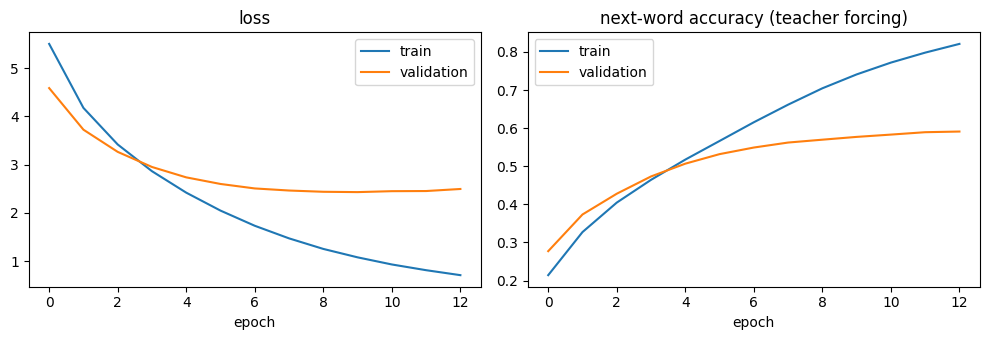

In [10]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["masked_acc"], label="train"); ax[1].plot(h["val_masked_acc"], label="validation")
ax[1].set_title("next-word accuracy (teacher forcing)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"results/{NAME}_curves.png", dpi=150); plt.show()

## 5. Translate (greedy decoding)
In training the decoder reads the *correct* previous word (teacher forcing). When we translate there is no
correct answer: the decoder must read **its own** previous word. So translation is a loop:
`[start]` → predict a word → append it → predict the next one … until `[end]`.

In [11]:
def to_words(ids):
    words = []
    for t in ids:
        if t == END or t == 0:
            break
        words.append(tgt_words[t])
    return " ".join(words)

def translate(sentences, chunk=512):
    """Greedy decoding: start with [start], predict the most likely word, append it, repeat."""
    out = []
    for k in range(0, len(sentences), chunk):
        part = [prepare_source(s) for s in sentences[k:k + chunk]]
        src = src_vec(part).numpy()
        dec = np.zeros((len(part), TGT_LEN - 1), dtype="int64")
        dec[:, 0] = START
        for i in range(TGT_LEN - 2):
            logits = model([src, dec], training=False).numpy()  # (n, 12, N_TGT)
            dec[:, i + 1] = np.argmax(logits[:, i, :], axis=-1)  # the word predicted at step i
        out += [to_words(row[1:]) for row in dec]
    return out

### Beam search
Greedy decoding keeps only the best word at each step; one early mistake cannot be undone.
**Beam search** keeps the $k$ best *partial translations* (the "beam"). At each step every one of them is
extended with its $k$ most likely next words, and only the $k$ best of the $k\times k$ candidates survive.
The score of a translation is the sum of the log-probabilities of its words, divided by its length
(otherwise short translations always win). Sutskever et al. found that a beam of 2 already gave most
of the gain.

In [12]:
def beam_translate(sentence, k=4):
    src = src_vec([prepare_source(sentence)] * k).numpy()
    beams = [([START], 0.0)]                                     # (words so far, sum of log-probs)
    finished = []
    for i in range(TGT_LEN - 2):
        dec = np.zeros((k, TGT_LEN - 1), dtype="int64")
        for b, (words, _) in enumerate(beams):
            dec[b, :len(words)] = words
        logp = tf.nn.log_softmax(model([src, dec], training=False)[:, i, :]).numpy()
        candidates = []
        for b, (words, score) in enumerate(beams):
            for t in np.argsort(logp[b])[-k:]:                   # the k best next words of this beam
                candidates.append((words + [int(t)], score + logp[b, t]))
        candidates.sort(key=lambda c: c[1] / len(c[0]), reverse=True)
        beams = []
        for words, score in candidates:
            if words[-1] == END:
                finished.append((words, score / len(words)))     # complete: take it out of the beam
            else:
                beams.append((words, score))
            if len(beams) == k:
                break
        if not beams:
            break
    finished += [(w, s / len(w)) for w, s in beams]               # unfinished ones also compete
    best = max(finished, key=lambda f: f[1])[0]
    return to_words(best[1:])

for s in ["i am hungry", "i have never seen such a beautiful city"]:
    print(s, "->", translate([s])[0], "| beam:", beam_translate(s))

i am hungry -> tengo hambre | beam: tengo hambre
i have never seen such a beautiful city -> nunca he visto nunca una semana tan interesante | beam: nunca he visto alguna vez más interesante


## 6. Evaluate: BLEU on the 5,000 test sentences

In [13]:
def bleu(references, hypotheses, max_n=4):
    """Corpus BLEU (Papineni et al., 2002), 0-100, with one reference per sentence.
    Geometric mean of the 1- to 4-gram precisions, times a brevity penalty."""
    matches, totals = [0] * max_n, [0] * max_n
    ref_len = hyp_len = 0
    for ref, hyp in zip(references, hypotheses):
        ref, hyp = ref.split(), hyp.split()
        ref_len += len(ref); hyp_len += len(hyp)
        for n in range(1, max_n + 1):
            ref_ngrams = collections.Counter(tuple(ref[i:i + n]) for i in range(len(ref) - n + 1))
            hyp_ngrams = collections.Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            matches[n - 1] += sum(min(c, ref_ngrams[g]) for g, c in hyp_ngrams.items())  # clipped counts
            totals[n - 1] += max(len(hyp) - n + 1, 0)
    # precision of each n-gram order; "+1" smoothing for n > 1 so that one order without matches
    # (e.g. no 4-grams in a 3-word sentence) does not make the whole score 0
    precisions = [matches[0] / max(totals[0], 1)] +                  [(m + 1) / (t + 1) for m, t in zip(matches[1:], totals[1:])]
    if precisions[0] == 0:
        return 0.0
    log_precision = sum(math.log(p) for p in precisions) / max_n
    brevity = min(1.0, math.exp(1 - ref_len / max(hyp_len, 1)))         # penalise short translations
    return 100 * brevity * math.exp(log_precision)

print("identical  :", round(bleu(["yo tengo hambre"], ["yo tengo hambre"]), 1))
print("one word   :", round(bleu(["el gato está en la mesa"], ["el perro está en la mesa"]), 1))

identical  : 100.0
one word   : 63.9


In [14]:
N_TEST = 500 if QUICK else len(test)
refs = list(test.es[:N_TEST])
t0 = time.time()
hyps = translate(list(test.en[:N_TEST]))
print(f"translated {N_TEST:,} test sentences in {time.time() - t0:.0f} s")
test_bleu = bleu(refs, hyps)
exact = np.mean([r == h for r, h in zip(refs, hyps)]) * 100
print(f"{NAME}: test BLEU = {test_bleu:.1f} | exact matches = {exact:.1f}%")

# BLEU by length of the English sentence
lengths = np.array([len(s.split()) for s in test.en[:N_TEST]])
BUCKETS = [(1, 3), (4, 5), (6, 7), (8, 10)]
by_length = {}
for lo, hi in BUCKETS:
    idx = np.where((lengths >= lo) & (lengths <= hi))[0]
    by_length[f"{lo}-{hi}"] = round(bleu([refs[i] for i in idx], [hyps[i] for i in idx]), 1)
print("BLEU by English length:", by_length)

translated 5,000 test sentences in 37 s
nb5: test BLEU = 20.5 | exact matches = 7.8%
BLEU by English length: {'1-3': 25.2, '4-5': 24.5, '6-7': 21.5, '8-10': 15.5}


In [15]:
EXAMPLES = ["i am hungry", "where is the train station", "the cat is sleeping on the sofa",
            "she does not like coffee", "we will go to the beach tomorrow",
            "my brother has two children", "can you help me please",
            "i have never seen such a beautiful city"]
mine = translate(EXAMPLES)
some = test.sample(8, random_state=3)
theirs = translate(list(some.en))
table = pd.DataFrame({"English": EXAMPLES + list(some.en),
                      "model": mine + theirs,
                      "reference": [""] * len(EXAMPLES) + list(some.es)})
table.to_csv(f"results/{NAME}_examples.csv", index=False)
pd.set_option("display.max_colwidth", 60)
table

,English,model,reference
0,i am hungry,tengo hambre,
1,where is the train station,dónde está la estación de tren,
2,the cat is sleeping on the sofa,el gato está durmiendo en el sofá,
3,she does not like coffee,ella no me gusta el café,
4,we will go to the beach tomorrow,vamos a la iglesia mañana,
5,my brother has two children,mi hermano tiene dos hijos,
6,can you help me please,podrías ayudarme por favor,
7,i have never seen such a beautiful city,nunca he visto nunca una semana tan interesante,
8,i wash my face every morning,esta mañana me lavo las vacaciones,me lavo la cara cada mañana
9,why dont you wait outside,por qué no viniste a beber,por qué no esperás afuera


In [16]:
results = {"name": NAME, "model": MODEL_LABEL, "params": int(model.count_params()),
           "epochs": epochs_run, "minutes": round(minutes, 1),
           "s_per_epoch": round(60 * minutes / epochs_run),
           "val_acc": round(100 * max(history.history["val_masked_acc"]), 1),
           "bleu": round(test_bleu, 1), "exact": round(exact, 1), "bleu_by_length": by_length,
           "examples": dict(zip(EXAMPLES, mine))}
json.dump(results, open(f"results/{NAME}_results.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(results, indent=2, ensure_ascii=False))
print(f">>> for the slides: params = {results['params']:,} | val next-word acc = {results['val_acc']}% | "
      f"test BLEU = {results['bleu']} | exact = {results['exact']}% | "
      f"training time = {results['minutes']} min ({results['s_per_epoch']} s/epoch)")

{
  "name": "nb5",
  "model": "Sutskever: 2-layer LSTM, reversed source",
  "params": 21281432,
  "epochs": 13,
  "minutes": 19.2,
  "s_per_epoch": 88,
  "val_acc": 59.1,
  "bleu": 20.5,
  "exact": 7.8,
  "bleu_by_length": {
    "1-3": 25.2,
    "4-5": 24.5,
    "6-7": 21.5,
    "8-10": 15.5
  },
  "examples": {
    "i am hungry": "tengo hambre",
    "where is the train station": "dónde está la estación de tren",
    "the cat is sleeping on the sofa": "el gato está durmiendo en el sofá",
    "she does not like coffee": "ella no me gusta el café",
    "we will go to the beach tomorrow": "vamos a la iglesia mañana",
    "my brother has two children": "mi hermano tiene dos hijos",
    "can you help me please": "podrías ayudarme por favor",
    "i have never seen such a beautiful city": "nunca he visto nunca una semana tan interesante"
  }
}
>>> for the slides: params = 21,281,432 | val next-word acc = 59.1% | test BLEU = 20.5 | exact = 7.8% | training time = 19.2 min (88 s/epoch)


### Greedy vs beam search
Beam search runs one sentence at a time, so we use the first 1,000 test sentences (a few minutes on a GPU).

In [17]:
N_BEAM = 100 if QUICK else 1000
refs_b = list(test.es[:N_BEAM])
greedy_b = hyps[:N_BEAM]
t0 = time.time()
beam_b = [beam_translate(s, k=4) for s in test.en[:N_BEAM]]
print(f"beam search: {time.time() - t0:.0f} s for {N_BEAM} sentences")
beam_bleu = bleu(refs_b, beam_b)
greedy_bleu = bleu(refs_b, greedy_b)
print(f"first {N_BEAM} test sentences: greedy BLEU = {greedy_bleu:.1f} | beam (k=4) BLEU = {beam_bleu:.1f}")
results.update({"greedy_bleu_1000": round(greedy_bleu, 1), "beam_bleu_1000": round(beam_bleu, 1)})
json.dump(results, open(f"results/{NAME}_results.json", "w"), indent=2, ensure_ascii=False)
print(f">>> for the slides: greedy BLEU (1000) = {greedy_bleu:.1f} | beam BLEU (1000) = {beam_bleu:.1f}")
changed = [(s, g, b) for s, g, b in zip(test.en[:N_BEAM], greedy_b, beam_b) if g != b]
pd.DataFrame(changed[:10], columns=["English", "greedy", "beam"])

beam search: 846 s for 1000 sentences
first 1000 test sentences: greedy BLEU = 21.3 | beam (k=4) BLEU = 23.2
>>> for the slides: greedy BLEU (1000) = 21.3 | beam BLEU (1000) = 23.2


,English,greedy,beam
0,i cant do it alone you have to help me,no puedo decirte que me iría hablando,no puedo decirte que me vaya a ayudarme
1,tom knew what mary had in mind,tom sabía lo que estaba buscando mary,tom sabía lo que mary tenía en mente
2,he comes here every three days,él viene aquí cada días,él viene aquí todos los días
3,he had an accident and fractured his leg,él tenía un poco de [UNK] en su pierna,él llevaba un gran tirón a su cara
4,im glad to hear that she is unmarried,me alegro de que él haya escuchado no se siente,me alegra que dejaras de que él está muerto
5,i dont actually have them,no me siento como los demás,no me siento nada
6,yesterday tom stayed home all day,a tom se miran todo el día en casa,a tom vuelve a casa todo el día
7,we were having an argument,nos hemos tomado una discusión,estábamos teniendo una discusión
8,we elected her mayor,lo elegimos sus ropas,nosotros lo elegimos alcalde
9,im afraid of wild animals,estoy comiendo muchas flores,tengo miedo de los animales francesas


## 7. The whole ladder
This cell reads the `results/nb*_results.json` files of the five notebooks (copy them into `results/` if
you ran the notebooks on different machines) and draws the final comparison.

,notebook,model,weights,s/epoch,epochs,BLEU
0,1,aligned LSTM,"11,668,120",43,9,12.1
1,2,encoder-decoder GRU,"16,298,648",47,8,22.9
2,3,encoder-decoder LSTM,"17,083,032",48,10,20.5
3,4,bidirectional LSTM encoder,"16,558,744",58,10,23.4
4,5,"Sutskever: 2-layer LSTM, reversed source","21,281,432",88,13,20.5


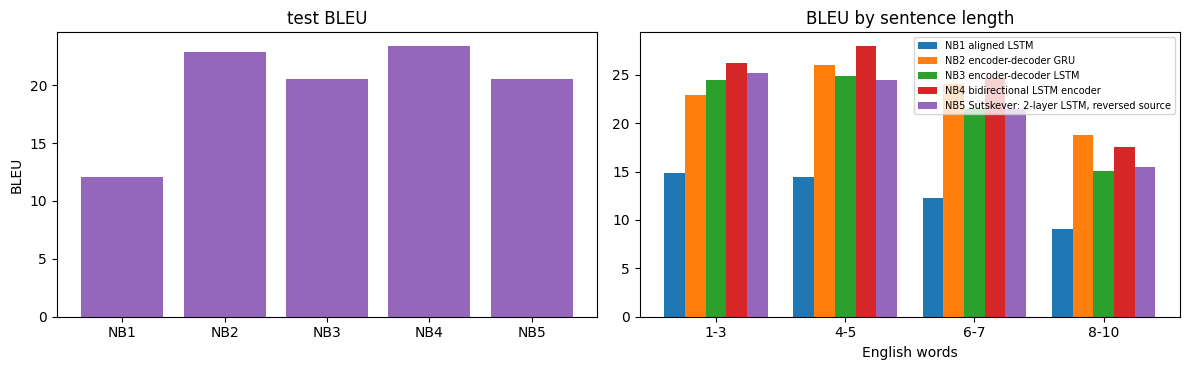

In [18]:
rows, by_len = [], {}
for n in range(1, 6):
    f = f"results/nb{n}_results.json"
    if os.path.exists(f):
        r = json.load(open(f))
        rows.append({"notebook": n, "model": r["model"], "weights": f"{r['params']:,}",
                     "s/epoch": r["s_per_epoch"], "epochs": r["epochs"], "BLEU": r["bleu"]})
        by_len[f"NB{n} {r['model']}"] = r["bleu_by_length"]
ladder = pd.DataFrame(rows)
display(ladder)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar([f"NB{r['notebook']}" for r in rows], [r["BLEU"] for r in rows], color="tab:purple")
ax[0].set_title("test BLEU"); ax[0].set_ylabel("BLEU")
buckets = list(next(iter(by_len.values())).keys())
w = 0.8 / len(by_len)
for j, (lab, d) in enumerate(by_len.items()):
    ax[1].bar(np.arange(len(buckets)) + j * w, [d[b] for b in buckets], w, label=lab)
ax[1].set_xticks(np.arange(len(buckets)) + 0.4 - w / 2, buckets)
ax[1].set_xlabel("English words"); ax[1].set_title("BLEU by sentence length"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/nb5_ladder.png", dpi=150); plt.show()

### Try it yourself
Set `REVERSE = False` in section 2 and run again: how much of the gain comes from the reversed source?

## Questions

1. Compare the final ladder: which step gave the largest gain? Which one the smallest?
2. Greedy vs beam: how many translations changed, and are the changes better?
3. Look at BLEU by length for all the models. Even the best model loses quality on longer sentences.
   Every model squeezes the sentence into one fixed vector: the **bottleneck**. Session 11 removes it
   with **attention**.